In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/healthcare_data_for_task - healthcare_data_for_task.csv")

In [ ]:
df.head()

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Medical_Code,Date_of_Admission,Discharge_Date,Admission_Type,Billing_Amount
0,P0001,47,Male,AB+,Heart Disease,HEA004,2025-05-10,2025-05-16,Emergency,23218.31
1,P0002,62,Female,AB-,Diabetes,DIA001,2025-12-31,2026-01-02,Emergency,47010.56
2,P0003,36,Male,AB-,Heart Disease,HEA004,2025-11-10,2025-11-27,Emergency,39619.01
3,P0004,51,Male,A+,Heart Disease,HEA004,2023-05-02,2023-05-07,Elective,35963.71
4,P0005,30,Male,A+,Diabetes,DIA001,2024-04-11,2024-04-17,Urgent,64615.93


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         1000 non-null   object 
 1   Age                1000 non-null   int64  
 2   Gender             1000 non-null   object 
 3   Blood_Type         1000 non-null   object 
 4   Medical_Condition  1000 non-null   object 
 5   Medical_Code       970 non-null    object 
 6   Date_of_Admission  1000 non-null   object 
 7   Discharge_Date     1000 non-null   object 
 8   Admission_Type     1000 non-null   object 
 9   Billing_Amount     1000 non-null   float64
dtypes: float64(1), int64(1), object(8)
memory usage: 78.3+ KB


In [ ]:
df.shape

(1000, 10)

In [ ]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition',
       'Medical_Code', 'Date_of_Admission', 'Discharge_Date', 'Admission_Type',
       'Billing_Amount'],
      dtype='object')

In [ ]:
df.describe()

,Age,Billing_Amount
count,1000.000000,1000.000000
mean,51.888000,77117.515720
std,19.256954,41955.242269
min,18.000000,5568.160000
25%,35.750000,40318.785000
50%,52.000000,77293.900000
75%,69.000000,113089.267500
max,85.000000,149921.800000


In [ ]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Blood_Type,0
Medical_Condition,0
Medical_Code,30
Date_of_Admission,0
Discharge_Date,0
Admission_Type,0
Billing_Amount,0


In [ ]:
df['Medical_Code']=df['Medical_Code'].fillna('Unknown')

In [ ]:
df.isnull().sum()

,0
Patient_ID,0
Age,0
Gender,0
Blood_Type,0
Medical_Condition,0
Medical_Code,0
Date_of_Admission,0
Discharge_Date,0
Admission_Type,0
Billing_Amount,0


In [ ]:
df['Date_of_Admission']=pd.to_datetime(df['Date_of_Admission'])

In [ ]:
df['Discharge_Date']=pd.to_datetime(df['Discharge_Date'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Patient_ID         1000 non-null   object        
 1   Age                1000 non-null   int64         
 2   Gender             1000 non-null   object        
 3   Blood_Type         1000 non-null   object        
 4   Medical_Condition  1000 non-null   object        
 5   Medical_Code       1000 non-null   object        
 6   Date_of_Admission  1000 non-null   datetime64[ns]
 7   Discharge_Date     1000 non-null   datetime64[ns]
 8   Admission_Type     1000 non-null   object        
 9   Billing_Amount     1000 non-null   float64       
dtypes: datetime64[ns](2), float64(1), int64(1), object(6)
memory usage: 78.3+ KB


In [ ]:
df['Date_of_Admission'].dt.year

,Date_of_Admission
0,2025
1,2025
2,2025
3,2023
4,2024
...,...
995,2023
996,2025
997,2023
998,2023


In [ ]:
df['Date_of_Admission'].dt.month

,Date_of_Admission
0,5
1,12
2,11
3,5
4,4
...,...
995,3
996,4
997,5
998,2


In [ ]:
df['Date_of_Admission'].dt.day

,Date_of_Admission
0,10
1,31
2,10
3,2
4,11
...,...
995,16
996,17
997,8
998,11


In [ ]:
df['Stay_days'] = (df['Discharge_Date']-df['Date_of_Admission']).dt.days

In [ ]:
df['Admission_Type'].value_counts

<bound method IndexOpsMixin.value_counts of 0      Emergency
1      Emergency
2      Emergency
3       Elective
4         Urgent
         ...    
995    Emergency
996     Elective
997    EMERGENCY
998    Emergency
999       Urgent
Name: Admission_Type, Length: 1000, dtype: object>

In [ ]:
df['Admission_Type'].unique()

array(['Emergency', 'Elective', 'Urgent', 'urgent', 'ELECTIVE',
       'elective', 'URGENT', 'emergency', 'EMERGENCY'], dtype=object)

In [ ]:
df['Admission_Type']=(
    df['Admission_Type'].str.strip().str.title()
)

<Axes: xlabel='Admission_Type'>

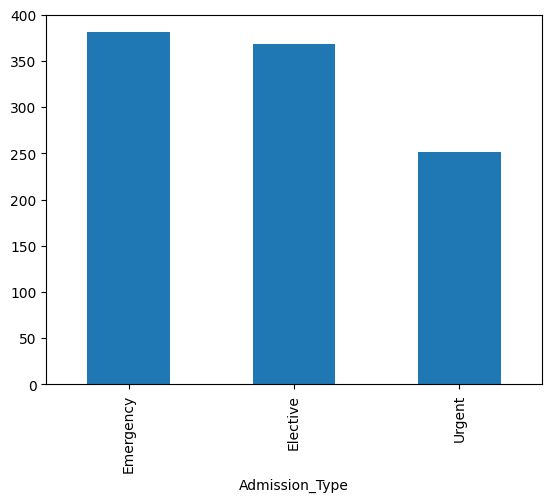

In [ ]:
df['Admission_Type'].value_counts().plot(kind='bar')

In [ ]:
numeric_df=df.select_dtypes(include="number")

In [ ]:
corr=numeric_df.corr()
corr

,Age,Billing_Amount,Stay_days
Age,1.000000,0.009515,0.019651
Billing_Amount,0.009515,1.000000,-0.040583
Stay_days,0.019651,-0.040583,1.000000


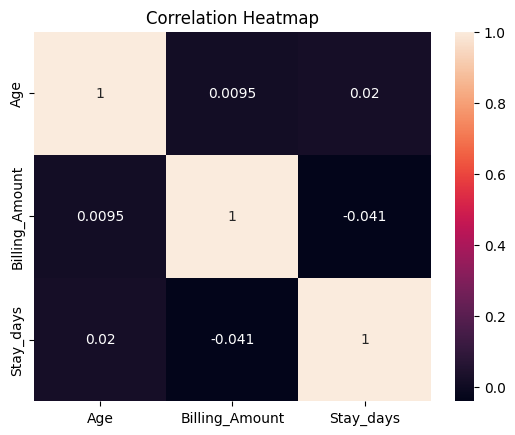

In [27]:
sns.heatmap(corr,annot=True)
plt.title("Correlation Heatmap")
plt.show()